# Plotting postprocessed data

Example of the analysis functions of `postprocessed_analysis.py` on the timestamp `1791789186`
(postprocessing folder, `compute_keywords=['static']`): 5 result files (one per grid, $N_t$ = 1501 ... 501 at fixed $T_{max}$),
each containing 12 temperatures.

| function | what it does |
|---|---|
| `detect_job_parameters` | which parameters vary inside a file (inner), differ between files (outer) or are constant |
| `plot_gap_vs_parameter` | $|\Delta|/T_c$ vs the inner parameter, one curve per file, legend = parameter that differs between files |
| `analyze_errors_vs_grid` | gap difference and normalization / FDT errors vs $dt$ (or $T_{max}$) with fitted exponents |
| `plot_green_function_rows` | $g^R(t=-1,t')$ and $g^K(t=-1,t')$, all components, real and imaginary |
| `plot_consistency_rows` | normalization and FDT error rows at $t=-1$ vs $t'$ with printed maxima |

In [25]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('/home/filip/Git_Code/')
sys.path.append('/home/filip/Documents/Research/Superconducting_vortices/Keldysh-non-eq/psBQP-keldysh/')

from demler_tools.file_manager import path_management

import postprocessed_analysis as pa

In [38]:
# Initialize demler_tools path management
path_management.initialize(project_name='psBQP-keldysh')

timestamp = '1792066919'#'1791905534'# '1791789186' modified, and it is a function of $t$ so a non-equilibrium loaded state works.

Successfully initialized path management with following parameters:
     username:                fmarijanovic
     project name:            psBQP-keldysh
     controlling machine:     laptop
     library version:         v2.3.0-beta-8-g6d57f9e
     auto SSH transfer:       True
     default save location:   /home/filip/Documents/Research/data_files/
     LTS mount point:         /home/filip
     email domain:            phys.ethz.ch
     cluster OS:              Ubuntu
     cluster partition:       work
     SSH host file:           /home/filip/.ssh/known_hosts
     SSH key file:            /home/filip/.ssh/id_ed25519_euler
     default modules:         {'CentOS': 'gcc/8.2.0 python/3.11.2', 'Ubuntu': 'stack/2024-06 python/3.11.6'}


## Which parameters differ between the jobs?

In [39]:
detection = pa.detect_job_parameters(timestamp)

Timestamp 1792066919: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer):
    dt: 0.0418879, 0.0628319
    time_sampling: 751, 501
  constant: FWHM = 20, critical_temperature = 1, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159


## Gap vs parameter (one curve per file, legend = parameter that differs between the files)

Timestamp 1792066919: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer):
    dt: 0.0418879, 0.0628319
    time_sampling: 751, 501
  constant: FWHM = 20, critical_temperature = 1, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159
  file 0, $N_t$ = 751, $\Delta t$ = 0.04189:
           amplitude       |gap|/T_c   std (last 50)
                   0  1.37861162e+00  4.02896738e-06
                0.05  1.37108443e+00  4.07329133e-06
                 0.1  1.34804601e+00  4.34234769e-06
                0.15  1.30799410e+00  3.93521008e-06
                 0.2  1.24802545e+00  3.69008846e-06
                0.25  1.16290954e+00  4.23982376e-06
                 0.3  1.04294128e+00  4.58864535e-06
                0.35  8.67474843e-01  3.43474541e-06
                 0.4  5.74681581e-01  8.45581113e-06
                0.45  1.75436378e-05  3.28209429e-06
                 0.5  5.88166190e-06  3.97181244e-06


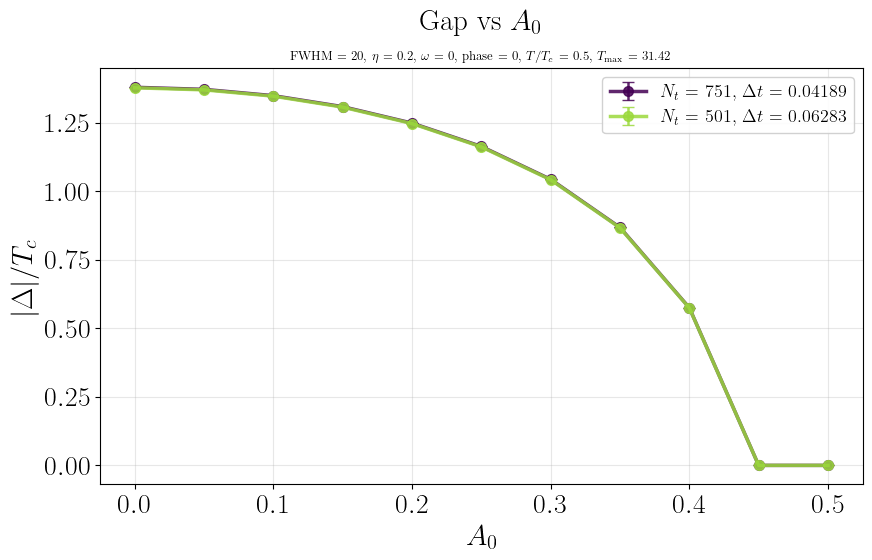

['$N_t$ = 751, $\\Delta t$ = 0.04189', '$N_t$ = 501, $\\Delta t$ = 0.06283']


'Timestamp 1791973293: 1 result file(s), indices [0]\n  varies inside each file (inner): amplitude\n  differs between files (outer): -\n  constant: FWHM = 20, critical_temperature = 1, dt = 0.0628319, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159, time_sampling = 501\n  file 0, file 0:\n           amplitude       |gap|/T_c\n                0.05  1.36406323e+00\n                 0.1  1.34013316e+00\n                0.15  1.29820482e+00\n                 0.2  1.23556085e+00\n                0.25  1.14653645e+00\n                 0.3  1.02103524e+00\n                0.35  8.39931732e-01\n                 0.4  5.58411865e-01\n                0.45  1.43096436e-01\n                 0.5  4.99884437e-03'

In [40]:
result = pa.plot_gap_vs_parameter(timestamp, save_plot=False)
print(result['labels'])

"""Timestamp 1791973293: 1 result file(s), indices [0]
  varies inside each file (inner): amplitude
  differs between files (outer): -
  constant: FWHM = 20, critical_temperature = 1, dt = 0.0628319, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159, time_sampling = 501
  file 0, file 0:
           amplitude       |gap|/T_c
                0.05  1.36406323e+00
                 0.1  1.34013316e+00
                0.15  1.29820482e+00
                 0.2  1.23556085e+00
                0.25  1.14653645e+00
                 0.3  1.02103524e+00
                0.35  8.39931732e-01
                 0.4  5.58411865e-01
                0.45  1.43096436e-01
                 0.5  4.99884437e-03"""

## Error analysis with $dt$

Gap difference to the finest grid, $g^R$ / $g^K$ normalization and FDT error at $(t,t')=(-1,-1)$ vs $dt$ for every temperature,
with the fitted exponents $p$ in error $\propto dt^p$. The $g^R$ normalization error is exactly zero at $(-1,-1)$ by construction, see the
profile plots below for the error along $t'$.

Timestamp 1792066919: 2 result file(s), indices [0, 1]
  varies inside each file (inner): amplitude
  differs between files (outer):
    dt: 0.0418879, 0.0628319
    time_sampling: 751, 501
  constant: FWHM = 20, critical_temperature = 1, eta = 0.2, frequency = 0, phase = 0, temperature = 0.5, time_duration = 31.4159


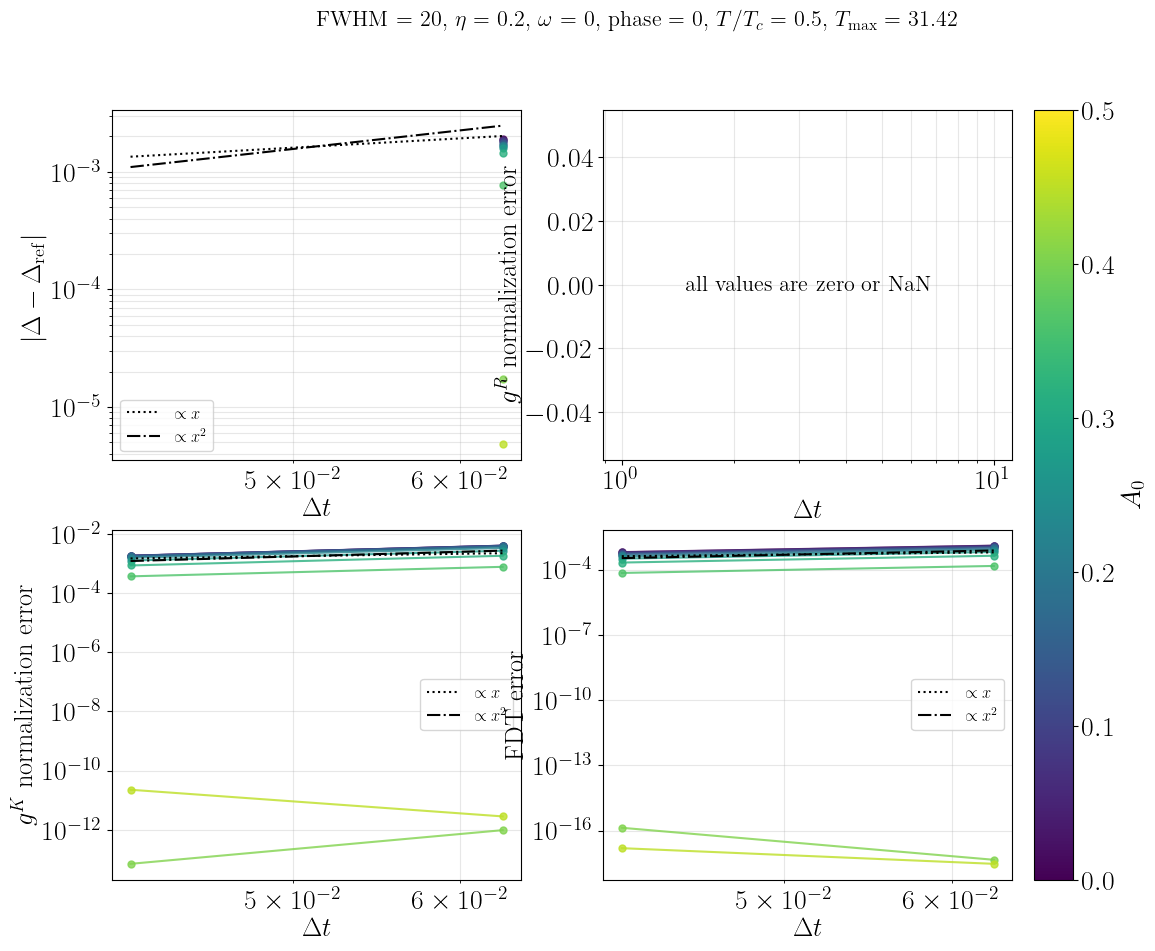

Fitted exponents p of error ~ dt^p (reference file index 0, dt = 0.04189, 0.06283)
     amplitude |    gap_difference |  gr_normalization |  gk_normalization |               fdt
             0 |               nan |               nan |              1.93 |              1.69
          0.05 |               nan |               nan |              1.93 |              1.69
           0.1 |               nan |               nan |              1.92 |              1.70
          0.15 |               nan |               nan |              1.92 |              1.70
           0.2 |               nan |               nan |              1.91 |              1.71
          0.25 |               nan |               nan |              1.89 |              1.73
           0.3 |               nan |               nan |              1.88 |              1.75
          0.35 |               nan |               nan |              1.86 |              1.77
           0.4 |               nan |               nan |      

In [41]:
errors = pa.analyze_errors_vs_grid(timestamp, save_plot=False)

## $g(t=-1,t')$ rows

The rows are saved by the `'static'` postprocessing (key `'rows'`). For older folders (like this one) the raw evolution run is used if it is
available locally; otherwise a message says what to copy or re-run. `directory_job_index` selects the file (grid), `job_index` the
temperature inside it.

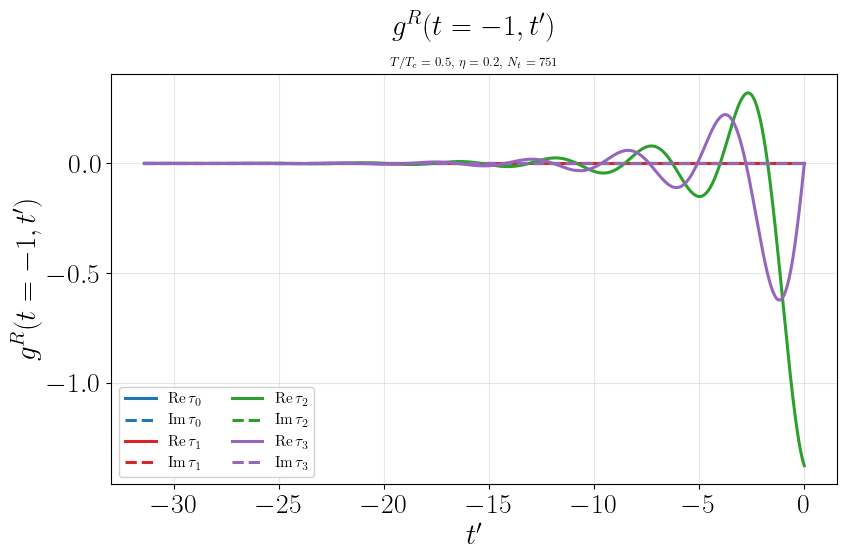

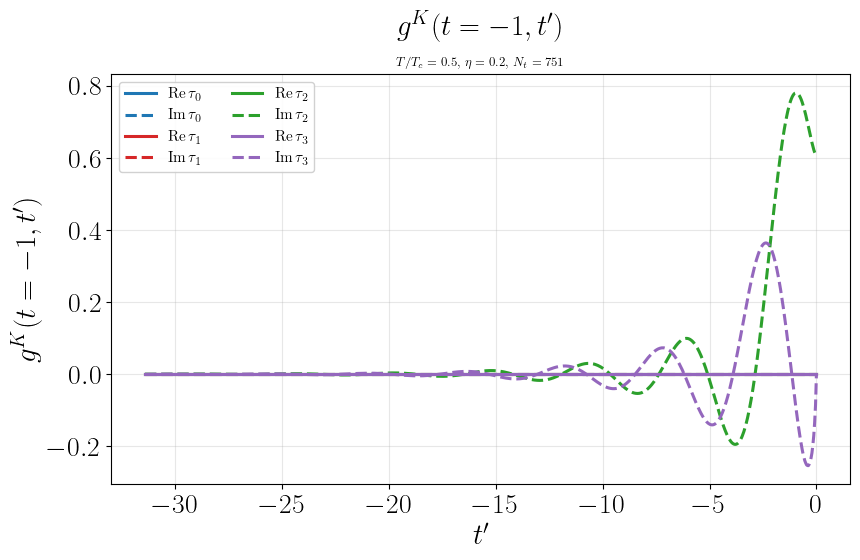

In [42]:
try:
    rows = pa.plot_green_function_rows(timestamp, directory_job_index=0, job_index=0, save_plot=False)
except FileNotFoundError as error:
    print(error)

## Normalization and FDT errors at $t=-1$ vs $t'$ (maximal errors are printed)

Maximal errors at t = -1 (timestamp 1792066919, file 0, job 5, source: rows)
  g^R normalization: max |error| = 2.370e-07 (Re tau_0, at t' = -0.042)
      Re tau_0: 2.370e-07 (t' = -0.042)
      Im tau_0: 3.231e-27 (t' = -3.854)
      Re tau_1: 2.070e-27 (t' = -4.817)
      Im tau_1: 5.262e-08 (t' = -1.801)
      Re tau_2: 1.665e-16 (t' = -2.429)
      Im tau_2: 4.275e-13 (t' = -0.796)
      Re tau_3: 3.331e-16 (t' = -2.471)
      Im tau_3: 2.170e-12 (t' = -0.042)
  g^K normalization: max |error| = 2.773e-03 (Im tau_0, at t' = -0.042)
      Re tau_0: 1.115e-15 (t' = -28.819)
      Im tau_0: 2.773e-03 (t' = -0.042)
      Re tau_1: 1.035e-06 (t' = -31.416)
      Im tau_1: 7.000e-17 (t' = -31.416)
      Re tau_2: 4.169e-14 (t' = -0.042)
      Im tau_2: 6.661e-16 (t' = -0.042)
      Re tau_3: 5.131e-11 (t' = -0.042)
      Im tau_3: 6.384e-16 (t' = -2.053)
  FDT: max |error| = 4.241e-04 (Im tau_3, at t' = -0.168)
      Re tau_0: 1.372e-11 (t' = 0.000)
      Im tau_0: 3.608e-16 (t' = -2.136)

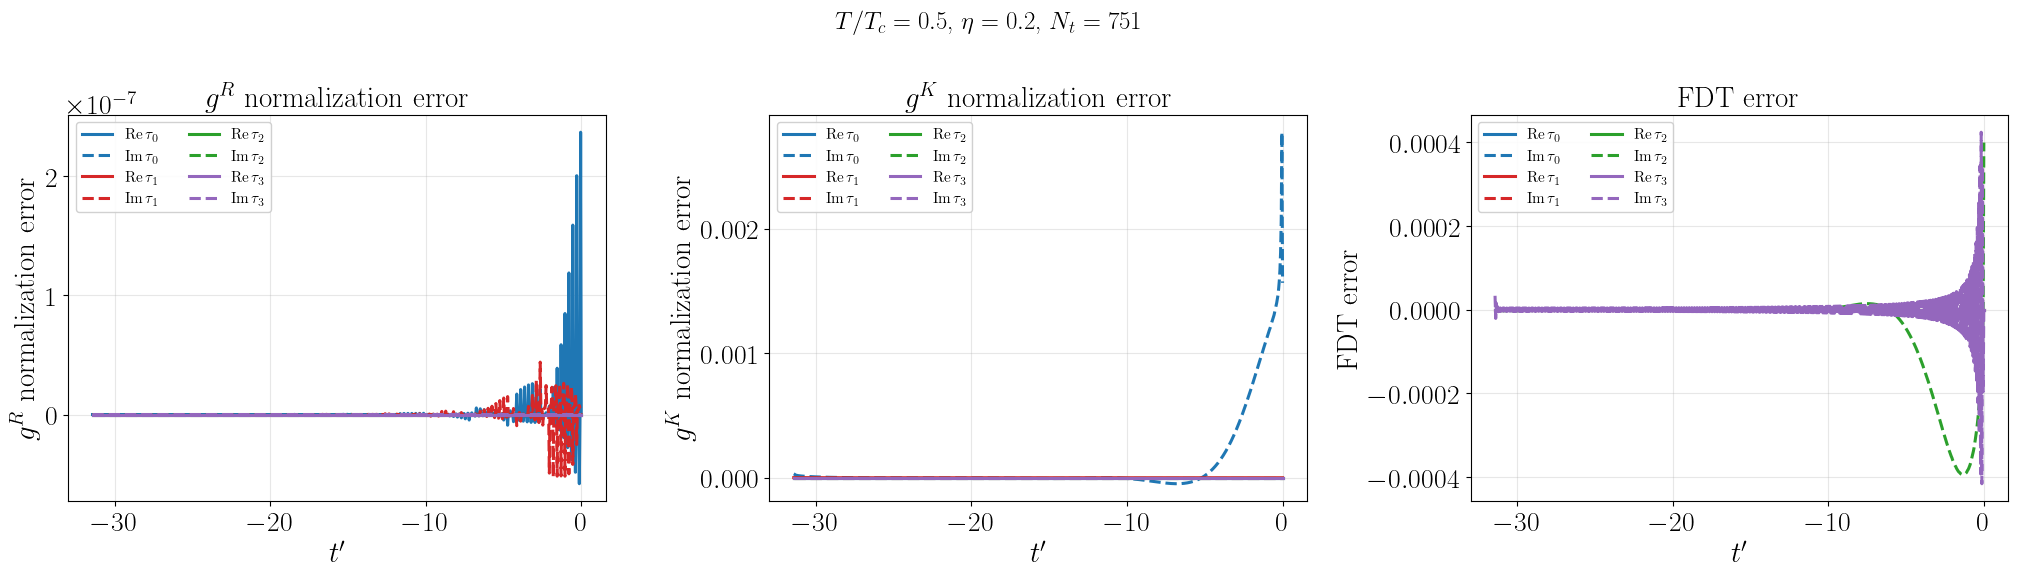

In [47]:
try:
    rows = pa.plot_consistency_rows(timestamp, directory_job_index=0, job_index=5, save_plot=False)
except FileNotFoundError as error:
    print(error)

### Getting the rows for this timestamp

Either copy the raw folders listed in the `calculation_arguments` of the postprocessing folder from the cluster to the local data folder, or
re-run the `'static'` postprocessing on the cluster (the rows are now saved by default).

# State evolution (timestamp from `compute_keywords=['state_evolution']`)

Time series of every job in a result file: gap, current and vector potential versus $t$. Use the timestamp of the postprocessing folder
created with `'state_evolution'`; the static-equilibrium timestamp above has no time series.

In [18]:
timestamp_evolution = '1792044298'  # replace by the timestamp of the 'state_evolution' postprocessing folder

## Gap deviation, current and vector potential vs time

`gap='deviation'` shows $(|\Delta(t)|-|\Delta(0)|)/T_c$, `'relative'` divides by $|\Delta(0)|$ and `'absolute'` shows $|\Delta(t)|/T_c$.
The legend lists the parameters that differ between the jobs of the file, `job_indices` selects a subset.

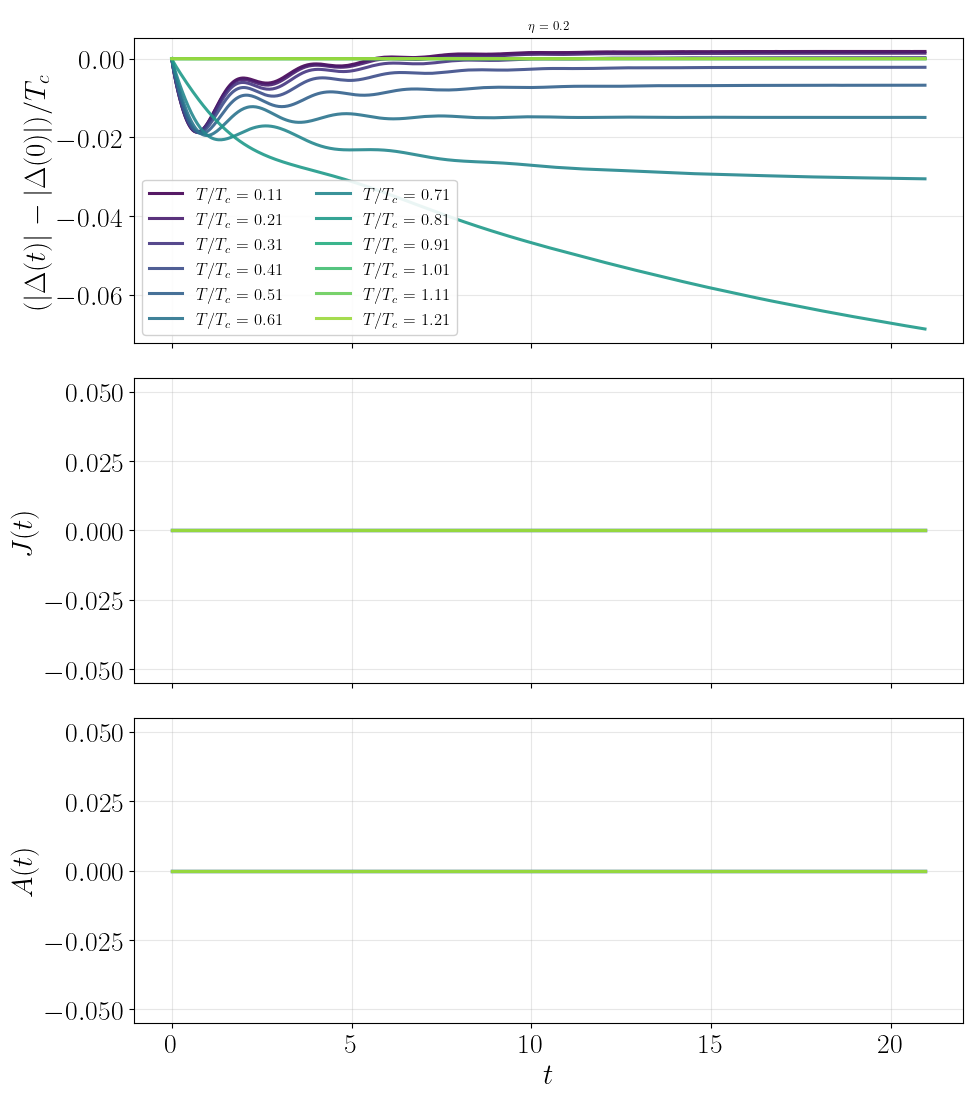

In [21]:
evolution = pa.plot_state_evolution(timestamp_evolution, directory_job_index=1, gap='deviation', save_plot=False)